# 07 - Train & compare all four architectures on DermaMNIST

Same four architectures as phase 1 (SimpleCNN, ResNet-18, ViT, MedViT simplified), now on a **multi-class, RGB, more imbalanced** subset. Everything reuses `src/` as-is — `build_model` already handles RGB input (`n_channels=3`) and multi-class tasks, and `evaluate`/`train_model` already adapt their loss and metrics to the task type automatically.

Instead of one notebook per model (as in phase 1, which was useful for a detailed first look at each architecture), this notebook loops over all four to keep the project maintainable as more subsets are added. See notebooks 02-05 for the detailed, step-by-step version.

In [1]:
import sys
sys.path.append("..")

import json
import time

import torch
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_dataloaders
from src.models import build_model
from src.train import train_model, evaluate_on_test
from src.utils import set_seed, get_device

set_seed(42)
device = get_device()
print("Using device:", device)


Using device: cuda


## 1. Load data

In [2]:
FLAG = "dermamnist"
SIZE = 28
BATCH_SIZE = 128

loaders, spec = get_dataloaders(FLAG, size=SIZE, batch_size=BATCH_SIZE,
                                root="../data", use_train_stats=True)
print(spec)

DatasetSpec(flag='dermamnist', task='multi-class', n_channels=3, n_classes=7, labels={'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'})


## 2. Train all four models

Same training routine (`train_model`) used for every architecture in phase 1; only the model and the subset (`FLAG`) change. Runtime will be longer here: more classes, RGB input, and a larger dataset than PneumoniaMNIST.

In [3]:
MODEL_NAMES = ["simple_cnn", "resnet18", "vit", "medvit"]
results = {}
histories = {}

for name in MODEL_NAMES:
    print(f"\n{'='*60}\nTraining {name} on {FLAG}\n{'='*60}")
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name}: {n_params:,} parameters")

    start = time.time()
    history = train_model(
        model, loaders, spec, device,
        epochs=15, lr=1e-3,
        out_dir="../results",
        run_name=f"{name}_{FLAG}",
        monitor="auc",
        early_stopping_patience=5,
    )
    elapsed = time.time() - start

    test_result = evaluate_on_test(model, loaders, spec, device,
                                   out_dir="../results", run_name=f"{name}_{FLAG}")
    results[name] = {**test_result.as_dict(), "n_params": n_params,
                     "train_time_s": round(elapsed, 1)}
    histories[name] = history
    print(f"{name} done in {elapsed/60:.1f} min")


Training simple_cnn on dermamnist
simple_cnn: 24,263 parameters


simple_cnn_dermamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[simple_cnn_dermamnist] epoch 01 | train loss 1.1990 | val auc 0.8490 (best)
[simple_cnn_dermamnist] epoch 02 | train loss 0.8738 | val auc 0.8799 (best)
[simple_cnn_dermamnist] epoch 03 | train loss 0.8201 | val auc 0.8753
[simple_cnn_dermamnist] epoch 04 | train loss 0.7838 | val auc 0.8854 (best)
[simple_cnn_dermamnist] epoch 05 | train loss 0.7687 | val auc 0.8898 (best)
[simple_cnn_dermamnist] epoch 06 | train loss 0.7519 | val auc 0.9054 (best)
[simple_cnn_dermamnist] epoch 07 | train loss 0.7366 | val auc 0.9100 (best)
[simple_cnn_dermamnist] epoch 08 | train loss 0.7341 | val auc 0.9104 (best)
[simple_cnn_dermamnist] epoch 09 | train loss 0.7178 | val auc 0.9119 (best)
[simple_cnn_dermamnist] epoch 10 | train loss 0.7087 | val auc 0.9211 (best)
[simple_cnn_dermamnist] epoch 11 | train loss 0.7019 | val auc 0.9193
[simple_cnn_dermamnist] epoch 12 | train loss 0.6922 | val auc 0.9100
[simple_cnn_dermamnist] epoch 13 | train loss 0.6854 | val auc 0.9124
[simple_cnn_dermamnist] epo

resnet18_dermamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[resnet18_dermamnist] epoch 01 | train loss 0.9760 | val auc 0.8699 (best)
[resnet18_dermamnist] epoch 02 | train loss 0.8165 | val auc 0.8936 (best)
[resnet18_dermamnist] epoch 03 | train loss 0.7819 | val auc 0.8971 (best)
[resnet18_dermamnist] epoch 04 | train loss 0.7457 | val auc 0.9075 (best)
[resnet18_dermamnist] epoch 05 | train loss 0.7094 | val auc 0.9126 (best)
[resnet18_dermamnist] epoch 06 | train loss 0.6812 | val auc 0.9176 (best)
[resnet18_dermamnist] epoch 07 | train loss 0.6496 | val auc 0.9142
[resnet18_dermamnist] epoch 08 | train loss 0.6442 | val auc 0.9200 (best)
[resnet18_dermamnist] epoch 09 | train loss 0.6184 | val auc 0.9138
[resnet18_dermamnist] epoch 10 | train loss 0.5842 | val auc 0.9239 (best)
[resnet18_dermamnist] epoch 11 | train loss 0.5375 | val auc 0.9301 (best)
[resnet18_dermamnist] epoch 12 | train loss 0.5344 | val auc 0.9253
[resnet18_dermamnist] epoch 13 | train loss 0.4801 | val auc 0.9113
[resnet18_dermamnist] epoch 14 | train loss 0.4276 | 

vit_dermamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[vit_dermamnist] epoch 01 | train loss 0.9734 | val auc 0.8407 (best)
[vit_dermamnist] epoch 02 | train loss 0.8485 | val auc 0.8789 (best)
[vit_dermamnist] epoch 03 | train loss 0.8054 | val auc 0.9036 (best)
[vit_dermamnist] epoch 04 | train loss 0.7614 | val auc 0.9146 (best)
[vit_dermamnist] epoch 05 | train loss 0.7304 | val auc 0.9153 (best)
[vit_dermamnist] epoch 06 | train loss 0.7165 | val auc 0.9201 (best)
[vit_dermamnist] epoch 07 | train loss 0.6954 | val auc 0.9240 (best)
[vit_dermamnist] epoch 08 | train loss 0.6933 | val auc 0.9265 (best)
[vit_dermamnist] epoch 09 | train loss 0.6645 | val auc 0.9288 (best)
[vit_dermamnist] epoch 10 | train loss 0.6531 | val auc 0.9292 (best)
[vit_dermamnist] epoch 11 | train loss 0.6425 | val auc 0.9304 (best)
[vit_dermamnist] epoch 12 | train loss 0.6377 | val auc 0.9327 (best)
[vit_dermamnist] epoch 13 | train loss 0.6203 | val auc 0.9315
[vit_dermamnist] epoch 14 | train loss 0.6175 | val auc 0.9297
[vit_dermamnist] epoch 15 | train 

medvit_dermamnist:   0%|          | 0/15 [00:00<?, ?it/s]

[medvit_dermamnist] epoch 01 | train loss 0.9054 | val auc 0.9072 (best)
[medvit_dermamnist] epoch 02 | train loss 0.7646 | val auc 0.9131 (best)
[medvit_dermamnist] epoch 03 | train loss 0.7023 | val auc 0.9151 (best)
[medvit_dermamnist] epoch 04 | train loss 0.6568 | val auc 0.9204 (best)
[medvit_dermamnist] epoch 05 | train loss 0.6345 | val auc 0.9049
[medvit_dermamnist] epoch 06 | train loss 0.5550 | val auc 0.9176
[medvit_dermamnist] epoch 07 | train loss 0.5187 | val auc 0.9130
[medvit_dermamnist] epoch 08 | train loss 0.4826 | val auc 0.9085
[medvit_dermamnist] epoch 09 | train loss 0.4343 | val auc 0.8920
[medvit_dermamnist] no improvement in 5 epochs, stopping early at epoch 9.
[medvit_dermamnist] loaded best checkpoint from epoch 4 (val auc=0.9204)
[medvit_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7431, balanced_accuracy=0.3808, auc=0.9097, f1=0.4260, majority_baseline_accuracy=0.6688)
medvit done in 3.8 min


## 3. Comparison table

In [4]:
comparison = pd.DataFrame(results).T
comparison = comparison[["n_params", "auc", "balanced_accuracy", "accuracy",
                         "f1", "train_time_s"]]
comparison.index.name = "model"
comparison

,n_params,auc,balanced_accuracy,accuracy,f1,train_time_s
model,,,,,,
simple_cnn,24263,0.906121,0.360463,0.72818,0.39788,346.4
resnet18,11172423,0.920974,0.500919,0.729177,0.503914,368.4
vit,140871,0.919701,0.45634,0.750623,0.487208,364.7
medvit,447975,0.909713,0.380796,0.743142,0.425993,229.2


## 4. AUC curves (validation) across models

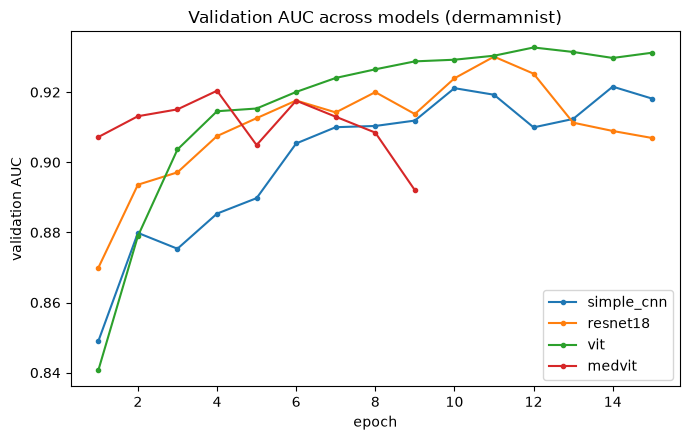

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in MODEL_NAMES:
    val_hist = histories[name]["val"]
    epochs_ran = [h["epoch"] for h in val_hist]
    ax.plot(epochs_ran, [h["auc"] for h in val_hist], label=name, marker="o", markersize=3)
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUC"); ax.legend()
ax.set_title(f"Validation AUC across models ({FLAG})")
plt.tight_layout(); plt.show()

## 5. Per-class performance (optional deep dive)

With 7 classes, an aggregate AUC/F1 can hide which specific lesion types each model struggles with. This loads each model's saved test metrics; the confusion matrix (saved inside each EvalResult, not in the JSON) would require re-running evaluation, so this cell focuses on the macro metrics already saved.

In [6]:
with open(f"../results/medvit_{FLAG}_test_metrics.json") as f:
    print(json.dumps(json.load(f), indent=2))

{
  "task": "multi-class",
  "accuracy": 0.743142144638404,
  "balanced_accuracy": 0.3807958102531348,
  "auc": 0.9097132288644365,
  "f1": 0.42599263588675557,
  "majority_baseline_accuracy": 0.6688279301745635
}


## 6. Compare with PneumoniaMNIST (phase 1) results

Does the pattern observed in phase 1 — more capacity not clearly helping, MedViT improving AUC over ViT but not fully closing the gap to the CNNs — repeat here, or does it change with more classes, RGB input and a larger, differently imbalanced dataset?

In [7]:
pneumonia_results = {}
for name in MODEL_NAMES:
    with open(f"../results/{name}_pneumoniamnist_test_metrics.json") as f:
        pneumonia_results[name] = json.load(f)

side_by_side = pd.DataFrame({
    "PneumoniaMNIST (AUC)": {n: pneumonia_results[n]["auc"] for n in MODEL_NAMES},
    "DermaMNIST (AUC)": {n: results[n]["auc"] for n in MODEL_NAMES},
    "PneumoniaMNIST (Bal. Acc)": {n: pneumonia_results[n]["balanced_accuracy"] for n in MODEL_NAMES},
    "DermaMNIST (Bal. Acc)": {n: results[n]["balanced_accuracy"] for n in MODEL_NAMES},
})
side_by_side

,PneumoniaMNIST (AUC),DermaMNIST (AUC),PneumoniaMNIST (Bal. Acc),DermaMNIST (Bal. Acc)
simple_cnn,0.968080,0.906121,0.824786,0.360463
resnet18,0.953408,0.920974,0.839316,0.500919
vit,0.956728,0.919701,0.750000,0.456340
medvit,0.962875,0.909713,0.761538,0.380796


## 7. Observations

## Per-class analysis (DermaMNIST)

Confusion matrices and per-class recall confirm the severity of the class
imbalance observed in the EDA: dermatofibroma (80 training images) has
recall 0.000 for both SimpleCNN and MedViT, and remains weak for ResNet-18
(0.130) and ViT (0.087) — essentially invisible to half the models tested.
Vascular lesions (99 images) fares better for ResNet-18 and ViT (0.690
recall each), showing that extreme rarity alone does not guarantee failure,
but SimpleCNN and MedViT still struggle (0.207 and 0.345).

ResNet-18 has the most balanced recall across all seven classes, explaining
its lead in balanced accuracy (0.501) — more model capacity appears to help
here, in contrast to PneumoniaMNIST's binary task, where it offered no clear
advantage. This suggests capacity requirements scale with task complexity
(more classes, more subtle inter-class differences), not just dataset size.

MedViT's confusion matrix shows a distinct error pattern: several classes
(e.g. basal cell carcinoma, actinic keratoses) are disproportionately
misclassified as "benign keratosis-like lesions" or "melanocytic nevi",
more so than in the other models. This may reflect the global average
pooling over tokens in the final stage homogenizing representations across
visually similar classes — a specific architectural limitation worth noting
alongside the project's broader finding that this simplified MedViT does not
consistently outperform simpler architectures.

## 8. Per-class confusion matrices (all four models)

Macro metrics (F1, balanced accuracy) can hide *which* classes a model fails on. This reloads each model's already-trained best checkpoint (no retraining needed) and plots the full 7x7 confusion matrix for each, to check whether rare classes (dermatofibroma, vascular lesions) are being predicted at all.

[simple_cnn_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7282, balanced_accuracy=0.3605, auc=0.9061, f1=0.3979, majority_baseline_accuracy=0.6688)
[resnet18_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7292, balanced_accuracy=0.5009, auc=0.9210, f1=0.5039, majority_baseline_accuracy=0.6688)
[vit_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7506, balanced_accuracy=0.4563, auc=0.9197, f1=0.4872, majority_baseline_accuracy=0.6688)
[medvit_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7431, balanced_accuracy=0.3808, auc=0.9097, f1=0.4260, majority_baseline_accuracy=0.6688)


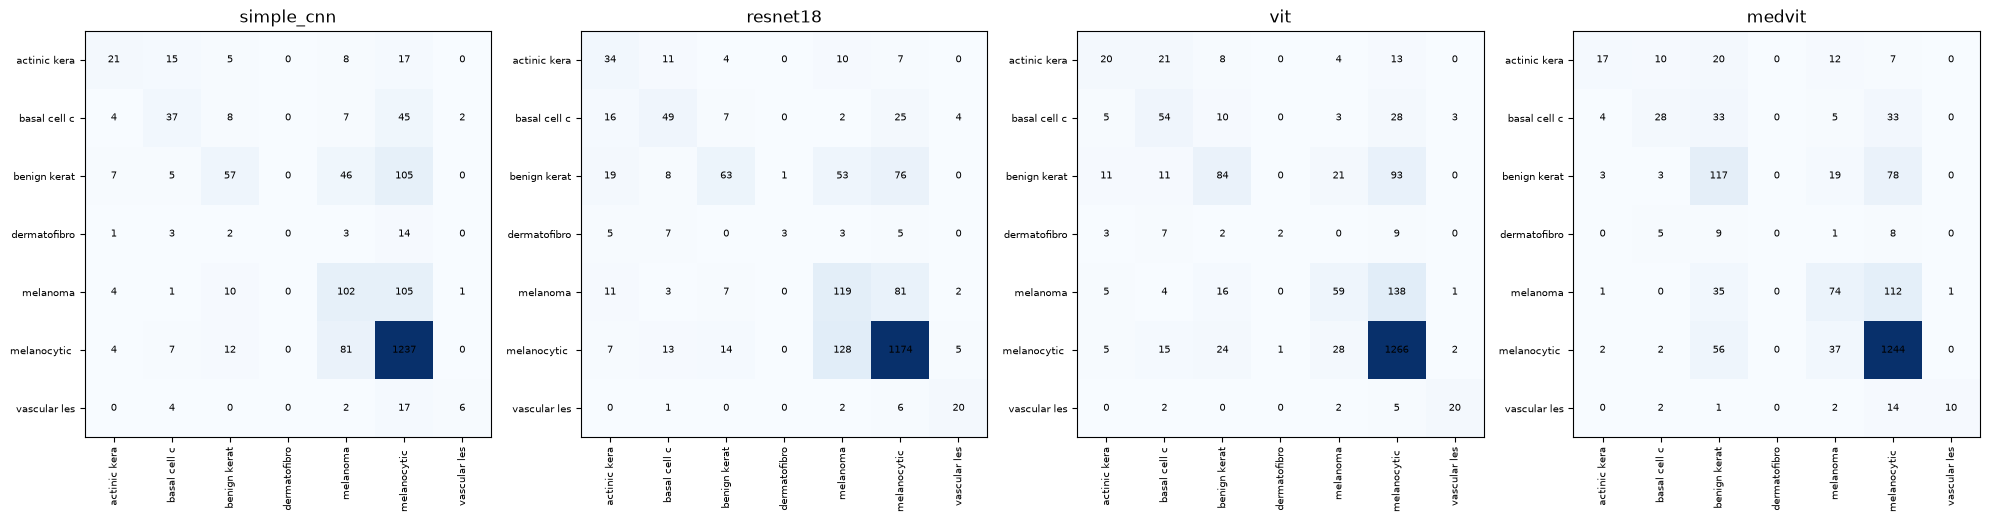

In [8]:
import torch.nn.functional as F

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
class_labels = [spec.labels[str(i)][:12] for i in range(spec.n_classes)]  # shortened for display

for ax, name in zip(axes, MODEL_NAMES):
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    model.load_state_dict(torch.load(f"../results/{name}_{FLAG}_best.pt", map_location=device))
    model.to(device)

    reeval = evaluate_on_test(model, loaders, spec, device,
                              out_dir="../results", run_name=f"{name}_{FLAG}")
    cm = reeval.confusion

    im = ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
    ax.set_xticks(range(spec.n_classes)); ax.set_xticklabels(class_labels, rotation=90, fontsize=7)
    ax.set_yticks(range(spec.n_classes)); ax.set_yticklabels(class_labels, fontsize=7)
    ax.set_title(name)

plt.tight_layout(); plt.show()

## 9. Recall per class (diagonal of the confusion matrix, normalized)

A direct view of whether each model predicts rare classes *at all* — look especially at the rows for dermatofibroma and vascular lesions (the two smallest classes, ~80-99 training images).

In [9]:
recall_table = {}
for name in MODEL_NAMES:
    model = build_model(name, n_channels=spec.n_channels, n_classes=spec.n_classes)
    model.load_state_dict(torch.load(f"../results/{name}_{FLAG}_best.pt", map_location=device))
    model.to(device)
    reeval = evaluate_on_test(model, loaders, spec, device,
                              out_dir="../results", run_name=f"{name}_{FLAG}")
    cm = reeval.confusion
    recall = cm.diagonal() / cm.sum(axis=1)
    recall_table[name] = recall

recall_df = pd.DataFrame(recall_table, index=[spec.labels[str(i)] for i in range(spec.n_classes)])
recall_df.round(3)

[simple_cnn_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7282, balanced_accuracy=0.3605, auc=0.9061, f1=0.3979, majority_baseline_accuracy=0.6688)
[resnet18_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7292, balanced_accuracy=0.5009, auc=0.9210, f1=0.5039, majority_baseline_accuracy=0.6688)
[vit_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7506, balanced_accuracy=0.4563, auc=0.9197, f1=0.4872, majority_baseline_accuracy=0.6688)
[medvit_dermamnist] TEST metrics: EvalResult(task=multi-class, accuracy=0.7431, balanced_accuracy=0.3808, auc=0.9097, f1=0.4260, majority_baseline_accuracy=0.6688)


,simple_cnn,resnet18,vit,medvit
actinic keratoses and intraepithelial carcinoma,0.318,0.515,0.303,0.258
basal cell carcinoma,0.359,0.476,0.524,0.272
benign keratosis-like lesions,0.259,0.286,0.382,0.532
dermatofibroma,0.000,0.130,0.087,0.000
melanoma,0.457,0.534,0.265,0.332
melanocytic nevi,0.922,0.875,0.944,0.928
vascular lesions,0.207,0.690,0.690,0.345
